In [2]:
import pandas as pd

df = pd.read_csv("../data/raw/products_train.csv")
df.shape

(23993, 6)

Convert the price text to a number

In [3]:
df["price"] = (
    df["Selling Price"]
    .astype(str)
    .str.replace(r"[$,]", "", regex=True)
)
df["price"] = pd.to_numeric(df["price"], errors="coerce")
df["price"].head()

0    14.47
1    12.74
2     9.06
3    27.85
4    28.92
Name: price, dtype: float64

Count failures

In [4]:
print("Missing before cleaning:", df["Selling Price"].isna().sum())
print("Missing after cleaning: ", df["price"].isna().sum())

Missing before cleaning: 186
Missing after cleaning:  1120


In [5]:
bad = df.loc[df["price"].isna(), "Selling Price"]
print(len(bad))
bad.value_counts().head(20)

1120


Selling Price
Total price:              115
Currently unavailable.     13
$14.99 $ 14 . 99           13
$24.99 $24.99              11
$39.99 $ 39 . 99           10
from 2 sellers              9
$ 59 99                     8
$399.00 $ 399 . 00          7
$53.00 - $71.75             6
$111.99 $111.99             6
$29.99 - $35.95             6
$17.99 - $39.99             6
$9.99 $ 9 . 99              6
$19.78 $ 19 . 78            6
$26.99 - $41.99             6
$748.00 - $2,024.91         6
$29.42 - $49.99             6
$10.49 $ 10 . 49            6
$32.53 - $35.26             6
$249.00 - $273.90           6
Name: count, dtype: int64

In [6]:
df = df.dropna(subset=["price"]).copy()
df.shape

(22873, 7)

In [7]:
df["price"].describe()

count    22873.000000
mean        44.385923
std        125.548793
min          0.990000
25%         11.120000
50%         18.990000
75%         34.990000
max       4199.000000
Name: price, dtype: float64

In [8]:
print(df["price"].sort_values().head(10).tolist())
print(df["price"].sort_values().tail(10).tolist())

[0.99, 1.07, 1.19, 1.19, 1.19, 1.28, 1.28, 1.28, 1.28, 1.41]
[2599.0, 2599.0, 2599.0, 2868.06, 2868.06, 2868.06, 2868.06, 3597.6, 4199.0, 4199.0]


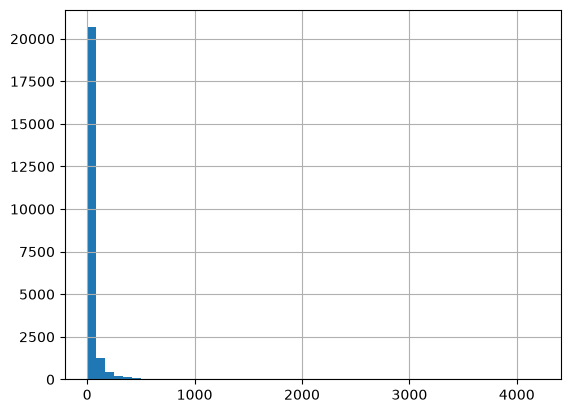

In [9]:
import matplotlib.pyplot as plt

df["price"].hist(bins=50)
plt.show()

In [10]:
df["main_category"] = df["Category"].astype(str).str.split("|").str[0].str.strip()
df["main_category"].value_counts()

main_category
Toys & Games                                15931
Home & Kitchen                               1663
Sports & Outdoors                            1146
Clothing, Shoes & Jewelry                     984
Baby Products                                 517
Arts, Crafts & Sewing                         263
Office Products                               105
Pet Supplies                                   54
Industrial & Scientific                        43
Health & Household                             41
Tools & Home Improvement                       37
Electronics                                    35
Hobbies                                        31
Beauty & Personal Care                         25
Patio, Lawn & Garden                           21
Grocery & Gourmet Food                         19
Video Games                                    18
Remote & App Controlled Vehicle Parts          17
Remote & App Controlled Vehicles & Parts       12
Automotive                          

In [11]:
import os
os.makedirs("../data/processed", exist_ok=True)
df.to_csv("../data/processed/products_train_clean.csv", index=False)

In [12]:
import re
import numpy as np

def parse_price(text):
    nums = re.findall(r"\$(\d[\d,]*\.\d{2})", str(text))
    if not nums:
        return np.nan
    vals = [float(n.replace(",", "")) for n in nums]
    return sum(vals) / len(vals)

df = pd.read_csv("../data/raw/products_train.csv")
df["price"] = df["Selling Price"].apply(parse_price)

print("Rows with a price now:", df["price"].notna().sum())
print("Previously:", 22873)

Rows with a price now: 23640
Previously: 22873


In [13]:
df = df.dropna(subset=["price"]).copy()
df["main_category"] = df["Category"].astype(str).str.split("|").str[0].str.strip()
df.to_csv("../data/processed/products_train_clean.csv", index=False)
df.shape

(23640, 8)

In [1]:
import pandas as pd
df = pd.read_csv("../data/processed/products_train_clean.csv")
print(df.shape)
print(df["sub_category"].value_counts().head(10))
print(df["desc_length"].describe())

(23640, 10)
sub_category
Games & Accessories             1537
Hobbies                         1398
Sports & Outdoor Play           1211
Arts & Crafts                   1189
Stuffed Animals & Plush Toys    1129
Toy Figures & Playsets          1117
Dress Up & Pretend Play         1088
Dolls & Accessories             1047
Costumes & Accessories          1023
Puzzles                         1021
Name: count, dtype: int64
count    23640.000000
mean        82.097547
std         59.322159
min          3.000000
25%         38.000000
50%         68.000000
75%        111.000000
max        545.000000
Name: desc_length, dtype: float64
